In [1]:
# Solving the committor equation using the diffusion map
import numpy as np
import scipy
import csv
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 20})

beta = 3

In [2]:
# The numpy-type potential function
def Vpot(xy):
    xa=-3
    ya=3
    xb=0 
    yb=4.5
    x = xy[:,0]
    y = xy[:,1]
    f=(1-x)**2+(y-0.25*x**2)**2+1
    g1=1-np.exp(-0.125*((x-xa)**2+(y-ya)**2))
    g2=1-np.exp(-0.25*(((x-xb)**2+(y-yb)**2)))
    g3=1.2-np.exp(-2*((x+0)**2+(y-2)**2))
    g4=1+np.exp(-2*(x+1.5)**2-(y-3.5)**2-(x+1)*(y-3.5))
    v = f*g1*g2*g3*g4
    return v

# define grid points
nx,ny= (100,100)
nxy = nx*ny
xmin = -4.5
xmax = 4
ymin = -3
ymax = 6
x1 = np.linspace(xmin,xmax,nx)
y1 = np.linspace(ymin,ymax,ny)
x_grid, y_grid = np.meshgrid(x1,y1)
x_vec = np.reshape(x_grid, (nxy,1))
y_vec = np.reshape(y_grid, (nxy,1))

v = np.zeros(nxy)
xy = np.concatenate((x_vec,y_vec),axis=1)
v = Vpot(xy)
v_grid = np.reshape(v,(nx,ny))    


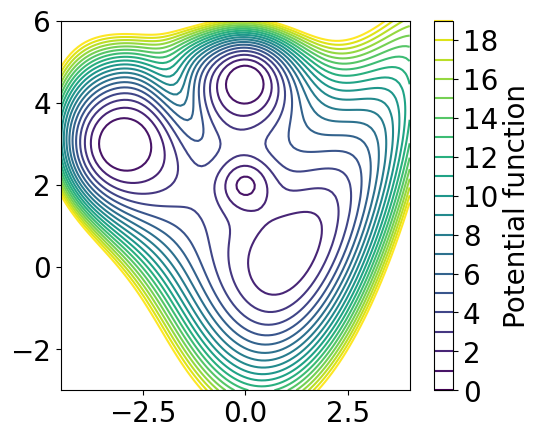

In [3]:
# plot face potential
ls = plt.contour(x_grid,y_grid,v_grid,range(0,20))
plt.colorbar(label="Potential function", orientation="vertical")
axes=plt.gca()
axes.set_aspect(1)


In [4]:
# import dataset
fdata_name = "Face_DeltaNet.npz"
data = np.load(fdata_name);
xy = data['delta_net']
# delta = data['delta']
delta = 0.05 # the parameter delta in delta-net
Ndata = np.size(xy,axis=0)
print(xy[0:10,:])

# define sets A and B
minimum_a = np.array([-3,3])
minimum_b = np.array([0,4.5])

ra = 0.5
rb = 0.5

# find indices of points in A and B and in OmegaAB
# Remove training points lying in the sets A and B
da2 = np.sum((xy - np.outer(np.ones((Ndata,)),minimum_a))**2,axis=1)
db2 = np.sum((xy - np.outer(np.ones((Ndata,)),minimum_b))**2,axis=1)
indA = np.argwhere(da2 < ra**2).ravel()
indB = np.argwhere(db2 < rb**2).ravel()
ind = np.arange(Ndata)
ind_OmegaAB = np.setdiff1d(ind, np.union1d(indA,indB))


[[-3.          3.        ]
 [-2.79207381  2.82768563]
 [-2.66896076  2.79594137]
 [-2.73213345  2.68044454]
 [-2.58848633  2.68847665]
 [-2.73909069  2.75955781]
 [-2.73512939  3.03589689]
 [-2.81253309  2.94962946]
 [-2.86034402  3.01683678]
 [-2.67426636  2.91826648]]


In [5]:
# the construction of the generator matrix
def make_generator(xy, eps_par, mu):
    r2 = 9*eps_par  # radius squared of the neighborhood (removed semicolon)
    
    # construct the similarity matrix
    N = np.size(xy, axis=0)
    e0 = np.ones((N,))
    
    # Use lil_matrix for efficient construction with indexing
    K = scipy.sparse.lil_matrix((N, N), dtype=float)
    
    for j in range(N):
        d2 = np.sum((xy-np.outer(e0, xy[j,:]))**2, axis=1)
        # Use ravel() to convert to 1D array of indices
        ind = np.argwhere(d2 - r2 < 0).ravel()
        K[j, ind] = np.exp(-d2[ind]/eps_par)
    
    # Convert to CSR format for efficient arithmetic operations
    K = K.tocsr()
    
    # kernel density estimation
    c = 2*np.pi*eps_par
    rho = np.sum(K, axis=1).A.ravel()/(N*c)  # .A converts to ndarray
    
    # right-normalize K
    D = scipy.sparse.diags(np.sqrt(mu)/rho, 0)
    K = K @ D
    
    # left-normalize K
    rho = np.sum(K, axis=1).A.ravel()  # row sums of K
    D = scipy.sparse.diags(1/rho, 0)
    P = D @ K
    
    # define the generator matrix
    L = (P-scipy.sparse.eye(N, N, k=0))/eps_par
    
    return L

In [6]:
# compute the invariant measure (the target measure)
mu = np.exp(-beta*Vpot(xy))
# define the kernel bandwidth parameter: k(x,y) = exp(-||x-y||^2 / eps_par)
eps_par = 1e-2
# construct the generator matrix
L = make_generator(xy,eps_par,mu)
q = np.zeros((Ndata,))
q[indB] = 1.
rhs = -np.sum(L[:,indB],axis = 1)
L_OmegaAB = L[ind_OmegaAB, :][:, ind_OmegaAB]
# find the committor
q[ind_OmegaAB] = scipy.sparse.linalg.spsolve(L_OmegaAB,rhs[ind_OmegaAB])


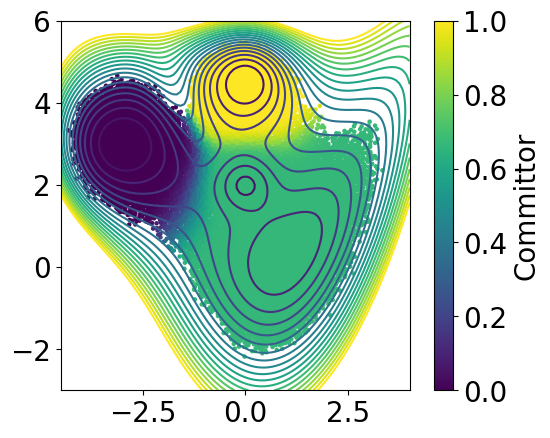

In [7]:
# plot the committor
ls = plt.contour(x_grid,y_grid,v_grid,range(0,20))
plt.scatter(xy[:,0],xy[:,1],c = q,s = 5)
plt.colorbar(label="Committor", orientation="vertical")
axes=plt.gca()
axes.set_aspect(1)
